In [2]:
import json
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torchvision.transforms as transforms 
import torchvision
import math
from sklearn.metrics import confusion_matrix
from torch.optim import Adam
from torch.utils.data import DataLoader, random_split 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [3]:
print("Tải dữ liệu và tính toán thông số chuẩn hóa...")

# Bước 1: Tải tập dữ liệu thô để tính mean và std chính xác (đã chia 255)
raw_train = torchvision.datasets.MNIST(root="./data", train=True, download=True)
raw_data_normalized = raw_train.data.float() / 255.0

pixel_mean = raw_data_normalized.mean().item()
pixel_std = raw_data_normalized.std().item()

print(f"Pixel Mean tính toán động: {pixel_mean:.4f}")
print(f"Pixel Std tính toán động: {pixel_std:.4f}")

# Bước 2: Tạo bộ transform động chuẩn hoá dữ liệu dựa trên mean và std tính toán
dynamic_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((pixel_mean,), (pixel_std,))
])

# Bước 3: Khởi tạo Dataset với transform chuẩn
train_dataset_original = torchvision.datasets.MNIST(
    root='./data', train=True, download=True, transform=dynamic_transform
)
test_dataset = torchvision.datasets.MNIST(
    root='./data', train=False, download=True, transform=dynamic_transform
)
train_size = int(0.9 * len(train_dataset_original))  # 54.000 mẫu
val_size = len(train_dataset_original) - train_size   # 6.000 mẫu
# Bước 4: Tạo DataLoader
batch_size = 64
train_dataset, val_dataset = random_split(train_dataset_original, [train_size, val_size])

train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)


Tải dữ liệu và tính toán thông số chuẩn hóa...
Pixel Mean tính toán động: 0.1307
Pixel Std tính toán động: 0.3081


In [4]:
class MNIST_GRU(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes):
        super(MNIST_GRU, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # x: (batch_size, 1, 28, 28) -> (batch_size, 28, 28)
        x = x.squeeze(1)  # Loại bỏ kênh màu (1)
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.gru(x, h0)  # out: (batch_size, seq_length=28, hidden_size)
        out = out[:, -1, :]  # Lấy output của bước thời gian cuối cùng
        out = self.fc(out)   # (batch_size, num_classes)
        return out

In [5]:
input_size = 28  # Each row of the image is treated as a time step
hidden_size = 128
num_layers = 2
num_classes = 10
lr = 0.001
epochs = 10
model = MNIST_GRU(input_size, hidden_size, num_layers, num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = Adam(model.parameters(), lr=lr)

In [6]:
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

print("Quá trình huấn luyện mô hình GRU Classifier...")
print("-" * 60)

for epoch in range(epochs):

    # Huấn luyện mô hình
    model.train()
    train_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    train_loss /= len(train_loader.dataset)
    train_acc = 100 * correct_train / total_train

    # Đánh giá mô hình trên tập validation
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    val_loss /= len(val_loader.dataset)
    val_acc = 100 * correct_val / total_val

    # Ghi lại lịch sử các chỉ số
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f"Epoch [{epoch+1}/{epochs}] - "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

Quá trình huấn luyện mô hình GRU Classifier...
------------------------------------------------------------
Epoch [1/10] - Train Loss: 0.3263, Train Acc: 89.58% | Val Loss: 0.0864, Val Acc: 97.27%
Epoch [2/10] - Train Loss: 0.0740, Train Acc: 97.72% | Val Loss: 0.0620, Val Acc: 98.07%
Epoch [3/10] - Train Loss: 0.0527, Train Acc: 98.41% | Val Loss: 0.0521, Val Acc: 98.47%
Epoch [4/10] - Train Loss: 0.0385, Train Acc: 98.81% | Val Loss: 0.0613, Val Acc: 98.22%
Epoch [5/10] - Train Loss: 0.0317, Train Acc: 99.05% | Val Loss: 0.0359, Val Acc: 98.92%
Epoch [6/10] - Train Loss: 0.0258, Train Acc: 99.18% | Val Loss: 0.0471, Val Acc: 98.72%
Epoch [7/10] - Train Loss: 0.0223, Train Acc: 99.33% | Val Loss: 0.0487, Val Acc: 98.65%
Epoch [8/10] - Train Loss: 0.0203, Train Acc: 99.34% | Val Loss: 0.0397, Val Acc: 98.82%
Epoch [9/10] - Train Loss: 0.0158, Train Acc: 99.49% | Val Loss: 0.0417, Val Acc: 98.68%
Epoch [10/10] - Train Loss: 0.0179, Train Acc: 99.42% | Val Loss: 0.0496, Val Acc: 98.75%


In [7]:
model.eval()
test_loss = 0.0
correct_final = 0
total_final = 0

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        
        # Tính toán loss cho tập test để lưu vào JSON
        loss = criterion(outputs, labels)
        test_loss += loss.item() * images.size(0)

        # Lấy nhãn dự đoán từ mô hình
        _, predicted = torch.max(outputs, 1)

        # Tính toán số lượng dự đoán đúng và tổng số mẫu
        total_final += labels.size(0)
        correct_final += (predicted == labels).sum().item()

        # Chuyển tensor về CPU và dạng list để lưu được vào JSON
        all_preds.extend(predicted.cpu().numpy().tolist())
        all_labels.extend(labels.cpu().numpy().tolist())

test_loss /= len(test_loader.dataset)
test_acc = 100 * correct_final / total_final

print(f"\n[Kết quả đánh giá trên tập test]")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}%")

history['final_test_loss'] = test_loss
history['final_test_acc'] = test_acc

# 2. Thêm dữ liệu ma trận nhầm lẫn vào dictionary lịch sử
history['confusion_matrix'] = {
    'true_labels': all_labels,
    'pred_labels': all_preds
}

# 3. Ghi toàn bộ dữ liệu vào file JSON (đã đổi tên cho đúng với GRU)
json_filename = "mnist_gru_results.json"
with open(json_filename, "w", encoding="utf-8") as f:
    json.dump(history, f, indent=4)

print("-" * 60)
print(f"Đã lưu lịch sử huấn luyện và dữ liệu ma trận nhầm lẫn vào file: '{json_filename}'")


[Kết quả đánh giá trên tập test]
Test Loss: 0.0494
Test Accuracy: 98.66%
------------------------------------------------------------
Đã lưu lịch sử huấn luyện và dữ liệu ma trận nhầm lẫn vào file: 'mnist_gru_results.json'


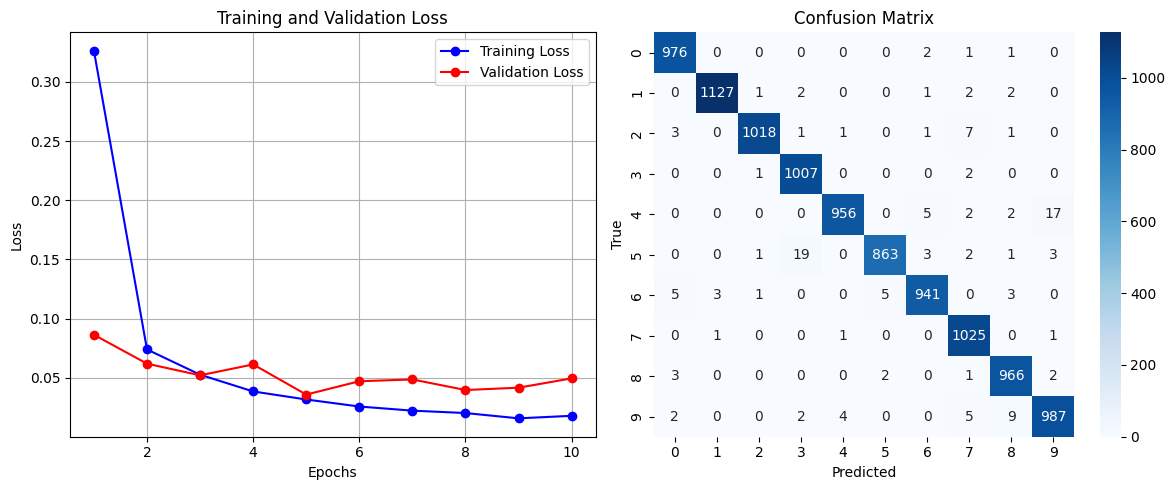

Đã vẽ và lưu đồ thị vào file 'mnist_gru_plots.png'


In [10]:
# 1. Đọc dữ liệu từ file JSON
with open("mnist_gru_results.json", "r") as f:
    data = json.load(f)

epochs = range(1, len(data['train_loss']) + 1)

# 2. Vẽ biểu đồ Training Loss vs Test Loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, data['train_loss'], 'b-o', label='Training Loss')
plt.plot(epochs, data['val_loss'], 'r-o', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# 3. Tính toán và vẽ Ma trận nhầm lẫn (Confusion Matrix)
true_labels = data['confusion_matrix']['true_labels']
pred_labels = data['confusion_matrix']['pred_labels']
cm = confusion_matrix(true_labels, pred_labels)

plt.subplot(1, 2, 2)
# Tạo nhãn từ 0 đến 9 cho MNIST
classes = [str(i) for i in range(10)]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')

plt.tight_layout()
# Lưu hình ảnh đồ thị ra file
plt.savefig('mnist_gru_plots.png', dpi=300)
plt.show()
print("Đã vẽ và lưu đồ thị vào file 'mnist_gru_plots.png'")
